# Task 1: DPO

This notebook runs independently and delegates experiments to task-specific Python modules.
The CPU diagnostics below validate mathematics/aggregation using explicitly labeled hand-authored fixtures;
they are **not** trained-model/course results. Actual course results are loaded from disk in the final cells.
No previous notebook state is required. Installation and full reproduction commands are in `RUNNING.md`.

The fixed prompts exceed the released 768-token cap. Full commands use a documented 4,096-token runtime override, preserving every prompt/example and the original configs. This increases compute and changes the released token budget; see RUNNING.md.


In [1]:
from pathlib import Path
import os, sys, shlex, subprocess
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "configs/base.yaml").exists()), None)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the repository or a task directory.")
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
for name, value in {
    "HF_HOME": ROOT / ".cache/huggingface", "HF_XET_CACHE": ROOT / ".cache/huggingface/xet",
    "MPLCONFIGDIR": ROOT / ".cache/matplotlib", "IPYTHONDIR": ROOT / ".cache/ipython",
}.items():
    os.environ.setdefault(name, str(value))
os.environ.setdefault("HF_HUB_DISABLE_XET", "1")
import torch
from IPython.display import display
from common.notebook_diagnostics import diagnostic
print("Repository:", ROOT)
print("Python:", sys.executable, "CUDA:", torch.cuda.is_available())
RUN_FULL_EXPERIMENTS = False  # Set True only when the required assets/models and compute are available.


/workspace/28100053-ATML-PA2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /workspace/28100053-ATML-PA2
Python: /workspace/28100053-ATML-PA2/.venv/bin/python CUDA: False


## CPU implementation diagnostic
These figures show equations or fixture behavior, with no simulated course metrics.

CPU DIAGNOSTIC ONLY — these outputs are not course training/evaluation results.
Policy equals reference: loss = 0.6931471824645996 ; chosen gradient = -0.05000000074505806 ; rejected gradient = 0.05000000074505806


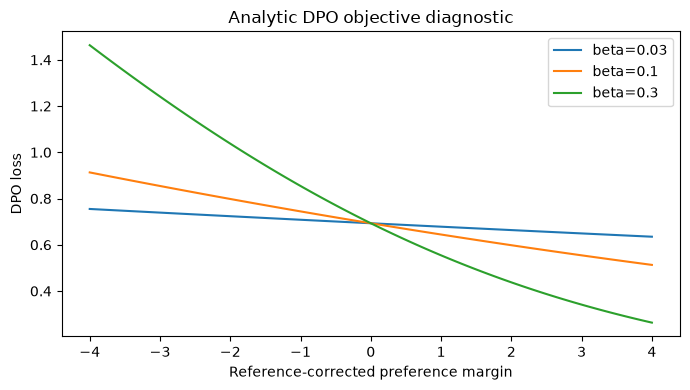

In [2]:
diagnostic_result = diagnostic(1)

## Fixed course data diagnostics
CPU checks on real downloaded assets; these do not claim trained-policy behavior.

,split,stratum,n
0,train,rejected_longer,500
1,train,preferred_longer,500
2,train,length_matched,500
3,eval,rejected_longer,82
4,eval,preferred_longer,82
5,eval,length_matched,82


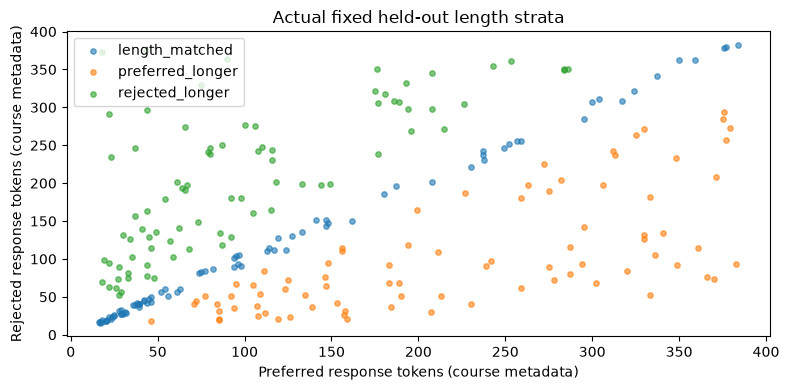

Held-out pair ID: 1858 Stratum: rejected_longer
Preferred excerpt: Afterschool Art and More contributes to the community as a grassroots organization by focusing on providing high-quality, personal, and professional enrichment programs in art, writing, and Spanish for children and adults. They create a calm, friendly environment free of judgment and competition, which encourages creative growth and learning. As a locally owned and operated business, they are dedi
Rejected excerpt: Afterschool Art and More contributes to the community as a grassroots organization by providing high quality, personal, and professional enrichment programming in ART, WRITING, and SPANISH. By offering a calm, friendly environment that is free of judgment and competition, the organization helps children and sometimes adults bloom creatively while learning the fundamentals of these subjects. Additi


In [3]:
from common.notebook_diagnostics import course_asset_diagnostic
course_asset_diagnostic(1)

## Full experiment commands
Commands fail on errors; required runs are never replaced by fixture diagnostics. Existing run directories are protected from accidental overwrite.

In [4]:
COMMANDS = ['python -m task1_dpo.experiments --mode standard --max-sequence-length 4096', 'python -m task1_dpo.experiments --mode beta --max-sequence-length 4096', 'python -m task1_dpo.experiments --mode length --max-sequence-length 4096']
for command in COMMANDS:
    print(command)
if RUN_FULL_EXPERIMENTS:
    for command in COMMANDS:
        args = shlex.split(command)
        args[0] = sys.executable
        subprocess.run(args, cwd=ROOT, check=True)
else:
    print("Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.")


python -m task1_dpo.experiments --mode standard --max-sequence-length 4096
python -m task1_dpo.experiments --mode beta --max-sequence-length 4096
python -m task1_dpo.experiments --mode length --max-sequence-length 4096
Full experiment execution is disabled. Set RUN_FULL_EXPERIMENTS=True to run the commands above.


## Saved course results and examples
Missing results are explicitly reported. Plots use the saved JSON/JSONL logs from actual runs.

In [5]:
from common.visualization import plot_task
plot_task(1)

""
